# Flow matching against diffusion, on a problem small enough to see

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/2_models/04_flow_matching_vs_diffusion.ipynb) &nbsp; Guide note: [guide-generative-modeling](https://www.matthewwnuk.com/guide-generative-modeling.html)

Two copies of one small network learn the same two-dimensional dataset. One is trained with a diffusion
loss and one with a flow-matching loss. Everything can be plotted: the training targets, the paths
samples take from noise to data, and how quality depends on the number of sampling steps.

By default the notebook loads trained weights. Set `TRAIN = True` to train both, which takes about a
minute on a GPU and a few on a CPU.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

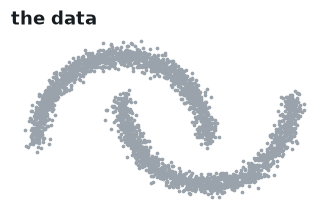

In [2]:
import os, math, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from guide_utils import data, style
style.use(); dev = "cuda" if torch.cuda.is_available() else "cpu"
TRAIN = False

def moons(n, seed):
    """Two interleaved crescents."""
    g = torch.Generator().manual_seed(seed); t = torch.rand(n, generator=g) * math.pi; up = torch.rand(n, generator=g) < 0.5
    x = torch.where(up, torch.cos(t), 1 - torch.cos(t)); y = torch.where(up, torch.sin(t), 0.5 - torch.sin(t))
    return ((torch.stack([x - 0.5, y - 0.25], 1) + 0.06 * torch.randn(n, 2, generator=g)) * 1.4).to(dev)

train_data, ref = moons(20000, 0), moons(3000, 1)
plt.figure(figsize=(3.6, 3.2)); plt.scatter(*ref.cpu().T, s=2, color=style.GREY); plt.gca().set_aspect("equal"); style.bare(plt.gca()); plt.title("the data"); plt.show()

## One network, two objectives

The network takes a point and a time and outputs a two-dimensional vector.

**Flow matching.** Draw noise `x0` and data `x1`, pick a time `t`, and place a point on the straight
line between them. The target is the direction of that line, `x1 - x0`.

**Diffusion.** Pick a noise level, mix data and noise in the proportions the schedule gives, and ask the
network for the noise that was added.

In [3]:
class Net(nn.Module):
    def __init__(self):
        super().__init__(); self.f = nn.Sequential(nn.Linear(3, 128), nn.SiLU(), nn.Linear(128, 128), nn.SiLU(), nn.Linear(128, 128), nn.SiLU(), nn.Linear(128, 2))
    def forward(self, x, t): return self.f(torch.cat([x, t[:, None]], 1))

T = 1000; betas = torch.linspace(1e-4, 0.02, T, device=dev); abar = torch.cumprod(1 - betas, 0)          # diffusion schedule

def flow_loss(net, x1):
    x0 = torch.randn_like(x1); t = torch.rand(len(x1), device=dev); xt = (1 - t[:, None]) * x0 + t[:, None] * x1
    return ((net(xt, t) - (x1 - x0)) ** 2).mean()

def diffusion_loss(net, x1):
    eps = torch.randn_like(x1); ti = torch.randint(0, T, (len(x1),), device=dev); a = abar[ti][:, None]
    return ((net(a.sqrt() * x1 + (1 - a).sqrt() * eps, ti.float() / T) - eps) ** 2).mean()

nets = {}
for name, loss_fn in (("flow", flow_loss), ("diffusion", diffusion_loss)):
    torch.manual_seed(0); net = Net().to(dev)
    if TRAIN:
        opt = torch.optim.Adam(net.parameters(), 2e-3)
        for it in range(6000):
            loss = loss_fn(net, train_data[torch.randint(0, len(train_data), (512,), device=dev)]); opt.zero_grad(); loss.backward(); opt.step()
        if os.environ.get("GUIDE_SAVE"): torch.save(net.state_dict(), os.path.join(os.environ["GUIDE_SAVE"], f"{name}.pt"))
    else:
        net.load_state_dict(torch.load(data.fetch_model(f"generative/{name}.pt"), map_location=dev))
    nets[name] = net.eval()

generative/flow.pt: reconstructing file:   0%|          |  0.00B /  138kB            

generative/flow.pt: downloading bytes:           |  0.00B            

generative/diffusion.pt: reconstructing file:   0%|          |  0.00B /  139kB            

generative/diffusion.pt: downloading bytes:           |  0.00B            

## Sampling

Flow matching integrates the learned velocity from t = 0 to 1 with Euler steps. Diffusion steps
backwards through the noise levels. The deterministic version is used here.

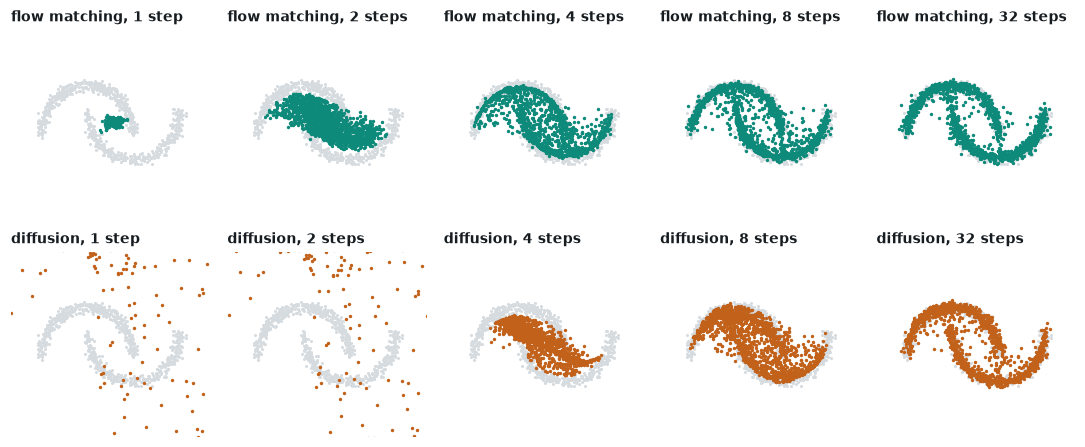

In [4]:
@torch.no_grad()
def sample_flow(n, steps, seed=5, keep=False):
    torch.manual_seed(seed); x = torch.randn(n, 2, device=dev); path = [x.cpu()]
    for i in range(steps):
        x = x + nets["flow"](x, torch.full((n,), i / steps, device=dev)) / steps; path.append(x.cpu())
    return (x, torch.stack(path)) if keep else x

@torch.no_grad()
def sample_diffusion(n, steps, seed=5, keep=False):
    torch.manual_seed(seed); x = torch.randn(n, 2, device=dev); ts = torch.linspace(T - 1, 0, steps).round().long().tolist(); path = [x.cpu()]
    for j, ti in enumerate(ts):
        a = abar[ti]; eps = nets["diffusion"](x, torch.full((n,), ti / T, device=dev)); x0 = ((x - (1 - a).sqrt() * eps) / a.sqrt()).clamp(-4, 4)
        a_prev = abar[ts[j + 1]] if j + 1 < len(ts) else torch.tensor(1.0, device=dev); x = a_prev.sqrt() * x0 + (1 - a_prev).sqrt() * eps; path.append(x.cpu())
    return (x, torch.stack(path)) if keep else x

fig, ax = plt.subplots(2, 5, figsize=(10, 4.2))
for r, (name, fn) in enumerate((("flow matching", sample_flow), ("diffusion", sample_diffusion))):
    for c, steps in enumerate((1, 2, 4, 8, 32)):
        s = fn(1500, steps).cpu(); ax[r, c].scatter(*ref.cpu()[:800].T, s=1, color="#D5DBDF"); ax[r, c].scatter(*s.T, s=1.5, color=style.TEAL if r == 0 else style.ORANGE)
        ax[r, c].set_xlim(-3, 3); ax[r, c].set_ylim(-2.6, 2.6); style.bare(ax[r, c]); ax[r, c].set_title(f"{name}, {steps} step{'s' if steps > 1 else ''}", fontsize=9)
plt.tight_layout(); plt.show()

## Quality against steps

The energy distance between generated samples and real data is zero when the two sets match. The dashed
line is the distance between two different sets of real data: the best any sampler could do.

flow matching  ['0.7398', '0.1685', '0.0367', '0.0096', '0.0050', '0.0042', '0.0041']
diffusion      ['4.0096', '3.9047', '0.1808', '0.0343', '0.0074', '0.0034', '0.0053']


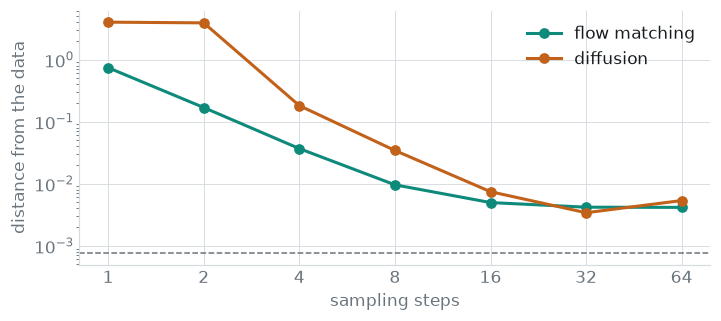

In [5]:
def energy(a, b): return (2 * torch.cdist(a, b).mean() - torch.cdist(a, a).mean() - torch.cdist(b, b).mean()).item()
steps = [1, 2, 4, 8, 16, 32, 64]; plt.figure(figsize=(7.4, 3))
for name, fn in (("flow matching", sample_flow), ("diffusion", sample_diffusion)):
    e = [energy(fn(3000, s), ref) for s in steps]; plt.plot(steps, e, marker="o", label=name); print(f"{name:14s}", [f"{v:.4f}" for v in e])
plt.axhline(energy(moons(3000, 2), ref), color=style.MUTED, ls="--", lw=1); plt.xscale("log", base=2); plt.yscale("log"); plt.xticks(steps, steps); plt.xlabel("sampling steps"); plt.ylabel("distance from the data"); plt.legend(); plt.show()

## Why: the paths

Flow-matching paths are nearly straight, so a few large steps follow them well.

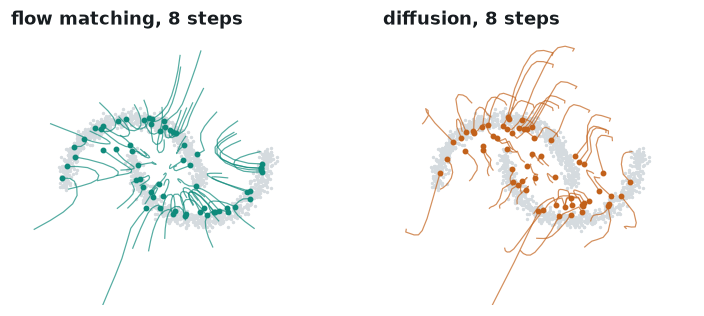

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3.6))
for a, (name, fn, c) in zip(ax, (("flow matching, 8 steps", sample_flow, style.TEAL), ("diffusion, 8 steps", sample_diffusion, style.ORANGE))):
    _, path = fn(60, 8, keep=True); a.scatter(*ref.cpu()[:1500].T, s=1.5, color="#D5DBDF")
    for k in range(60): a.plot(path[:, k, 0], path[:, k, 1], color=c, lw=0.8, alpha=0.7)
    a.scatter(*path[-1].T, s=8, color=c, zorder=3); a.set_xlim(-3.2, 3.2); a.set_ylim(-2.8, 2.8); a.set_aspect("equal"); style.bare(a); a.set_title(name)
plt.show()

## Things to try

- Set `TRAIN = True` and train for 500 steps instead of 6,000. Which method degrades more gracefully?
- Condition both models on which crescent a point belongs to, and generate one crescent on demand.
- Replace the Euler step with a midpoint step. How many steps does flow matching need now?